# 00 Pipeline overview: a toy room with known answers

**Slice.** A toy room (four walls, a slab, a door, plus a short partition wall that registration needs; see section 1) written as a real IFC with `ifcopenshell.api`. A synthetic scan is sampled from an as-built copy of it in which one wall stands 4 cm off, then given a known rigid transform.

**Question.** Can the whole chain (registration, per-element comparison, report, BCF issue) be run by hand, and does it return the known answers?

The known answers are asserted inside this notebook:

- registration recovers the known transform within the gate set for notebook 05 (rotation error at most 2°, translation error at most 5 cm);
- the moved wall gets the verdict **shifted** at about 40 mm, every other element is **OK**;
- the written IFC carries the verdicts, and the BCF file holds exactly one issue, for the moved wall.

No data is downloaded. Everything is seeded, so a re-run gives the same numbers.

In [1]:
import os
from pathlib import Path
import xml.etree.ElementTree as ET
import uuid
import zipfile

import ifcopenshell
import ifcopenshell.api
import ifcopenshell.guid
import ifcopenshell.util.element
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from bcf.v2.bcfxml import BcfXml
from IPython.display import Image, display

from scan_vs_bim.load import load_ifc_elements, merge_meshes

o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)  # quiet Open3D's info lines

# All parameters in one place. Lengths in metres.
SEED = 7
GUID_NAMESPACE = uuid.UUID("5ca17b13-0000-4000-8000-000000000000")  # fixed, so GlobalIds are the same on every run
OUT = Path("../outputs/00")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)

# Synthetic scan
SCANNER_POSITIONS = np.array([[1.2, 1.5, 1.4], [3.8, 2.4, 1.4]])  # where the simulated scanner stood (two positions, merged); used only to drop surfaces neither could see
N_SURFACE_SAMPLES = 150_000  # points sampled over the as-built surfaces before the visibility cut
SIGMA = 0.0025  # Gaussian range noise per axis, a TLS-like 2.5 mm
MOVED_WALL, SHIFT = "Wall East", np.array([-0.04, 0.0, 0.0])  # 4 cm into the room, perpendicular to its face
KNOWN_ROTATION_DEG = (3.0, -2.0, 10.0)  # about x, y, z
KNOWN_TRANSLATION = np.array([1.4, -0.9, 0.3])

# Registration (FPFH + RANSAC, then point-to-plane ICP)
N_MODEL_SAMPLES = 150_000
VOXEL = 0.15  # downsampling for the global step
NORMAL_RADIUS, FPFH_RADIUS = 2 * VOXEL, 5 * VOXEL
RANSAC_DIST, RANSAC_ITERS, RANSAC_CONFIDENCE = 1.5 * VOXEL, 200_000, 0.999
ICP_DIST = 0.10  # plain ICP: must exceed the 4 cm offset so the moved wall still gets correspondences
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust ICP: Tukey loss gives residuals beyond 2 cm no weight
GATE_ROT_DEG, GATE_TRANS_M = 2.0, 0.05  # the 05 gate from the roadmap

# Comparison
TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %)
BAND = 0.10  # scan points further than this from every element surface are ignored
MIN_POINTS = 200  # fewer points than this on an element: not enough to judge
MIN_FRAC_OK = 0.8  # share of points within tolerance for OK


## 1. The model: a room as a real IFC

A 5.0 x 4.0 m room with 0.2 m walls, 2.8 m high, on a slab that overhangs on two sides (so the room is not symmetric). The door is a thin box on the inside face of the south wall. A short partition wall stands off the north wall; it is there for registration, see section 3 (with only four walls, two of them opposite each other, one wall off by 4 cm cannot be told from its opposite wall being off). Elements are extruded rectangles, placed in a project / site / building / storey structure. The model is written to `outputs/00/toy_room.ifc` and read back with the package loader.

In [2]:
f = ifcopenshell.api.run("project.create_file")
project = ifcopenshell.api.run("root.create_entity", f, ifc_class="IfcProject", name="Toy room")
ifcopenshell.api.run("unit.assign_unit", f, length={"is_metric": True, "raw": "METERS"})
ctx = ifcopenshell.api.run("context.add_context", f, context_type="Model")
body = ifcopenshell.api.run("context.add_context", f, context_type="Model", context_identifier="Body",
                            target_view="MODEL_VIEW", parent=ctx)
site = ifcopenshell.api.run("root.create_entity", f, ifc_class="IfcSite", name="Site")
building = ifcopenshell.api.run("root.create_entity", f, ifc_class="IfcBuilding", name="Building")
storey = ifcopenshell.api.run("root.create_entity", f, ifc_class="IfcBuildingStorey", name="Ground floor")
ifcopenshell.api.run("aggregate.assign_object", f, products=[site], relating_object=project)
ifcopenshell.api.run("aggregate.assign_object", f, products=[building], relating_object=site)
ifcopenshell.api.run("aggregate.assign_object", f, products=[storey], relating_object=building)

# name, IFC class, size (x, y, z), origin of the box's lower corner
SPEC = [
    ("Wall South", "IfcWall", (5.2, 0.2, 2.8), (0.0, 0.0, 0.0)),
    ("Wall North", "IfcWall", (5.2, 0.2, 2.8), (0.0, 4.2, 0.0)),
    ("Wall West", "IfcWall", (0.2, 4.0, 2.8), (0.0, 0.2, 0.0)),
    ("Wall East", "IfcWall", (0.2, 4.0, 2.8), (5.0, 0.2, 0.0)),
    ("Slab", "IfcSlab", (5.8, 4.8, 0.2), (0.0, 0.0, -0.2)),
    ("Door", "IfcDoor", (0.9, 0.04, 2.1), (2.0, 0.2, 0.0)),
    ("Wall Partition", "IfcWall", (0.1, 1.6, 2.8), (2.5, 2.6, 0.0)),
]
for name, ifc_class, (x, y, z), origin in SPEC:
    el = ifcopenshell.api.run("root.create_entity", f, ifc_class=ifc_class, name=name)
    profile = f.createIfcRectangleProfileDef("AREA", None, f.createIfcAxis2Placement2D(f.createIfcCartesianPoint((x / 2, y / 2))), x, y)
    solid = f.createIfcExtrudedAreaSolid(profile, f.createIfcAxis2Placement3D(f.createIfcCartesianPoint((0.0, 0.0, 0.0))),
                                         f.createIfcDirection((0.0, 0.0, 1.0)), z)
    ifcopenshell.api.run("geometry.assign_representation", f, product=el,
                         representation=f.createIfcShapeRepresentation(body, "Body", "SweptSolid", [solid]))
    placement = np.eye(4)
    placement[:3, 3] = origin
    ifcopenshell.api.run("geometry.edit_object_placement", f, product=el, matrix=placement)
    ifcopenshell.api.run("spatial.assign_container", f, products=[el], relating_structure=storey)


def stable_guids(ifc_file):
    """Give every rooted entity a GlobalId derived from its name (or class and STEP id), so re-running changes nothing."""
    for entity in ifc_file.by_type("IfcRoot"):
        key = entity.Name or f"{entity.is_a()}#{entity.id()}"
        entity.GlobalId = ifcopenshell.guid.compress(uuid.uuid5(GUID_NAMESPACE, f"{entity.is_a()}:{key}").hex)


stable_guids(f)
guid_to_name = {el.GlobalId: el.Name for el in f.by_type("IfcElement")}
name_to_guid = {n: g for g, n in guid_to_name.items()}

MODEL_IFC = OUT / "toy_room.ifc"
f.write(str(MODEL_IFC))

elements = load_ifc_elements(MODEL_IFC)
model_mesh = merge_meshes(elements)
for e in elements:  # the verdict sign needs outward-facing triangles: check the winding once
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces))
    m.compute_triangle_normals()
    outward = np.einsum("ij,ij->i", e.vertices[e.faces].mean(1) - e.vertices.mean(0), np.asarray(m.triangle_normals))
    assert (outward > 0).all(), f"{guid_to_name[e.global_id]}: triangles face inward"
print(f"{len(elements)} elements, {len(model_mesh.triangles)} triangles")
for e in elements:
    print(f"  {e.global_id}  {e.ifc_class:8s} {guid_to_name[e.global_id]}")
assert {e.ifc_class for e in elements} == {"IfcWall", "IfcSlab", "IfcDoor"} and len(elements) == 7

7 elements, 84 triangles
  1QS95FRfDNohxeW4csKlou  IfcWall  Wall South
  2P8mr6uWrT5Q5p8AnSezIh  IfcWall  Wall North
  1fvsarFMjVLR$7DsPWlWb3  IfcWall  Wall West
  267XM8hxrIf9OKA6KcvPHU  IfcWall  Wall East
  0C9cNTKMDPcQ9sDN04AEKn  IfcSlab  Slab
  1w4lPfpA1IXAWaOonVXQfj  IfcDoor  Door
  0UU8SwUwrP_eOxjdnV7NWP  IfcWall  Wall Partition


## 2. The scan: as-built geometry, noise, a known transform

The scan is sampled from an **as-built** copy of the model in which `Wall East` is moved 4 cm into the room; the model itself is not touched. Only surfaces that one of two scanner positions in the room could see are kept (outer faces and faces hidden behind the door are dropped), then Gaussian noise of 2.5 mm is added per axis. Finally the scan is given a known rigid transform, so registration has something to recover.

In [3]:
rng = np.random.default_rng(SEED)
o3d.utility.random.seed(SEED)  # Open3D's RANSAC has its own RNG

# As-built geometry: same elements, one moved
as_built = [type(e)(e.global_id, e.ifc_class, e.vertices + (SHIFT if guid_to_name[e.global_id] == MOVED_WALL else 0), e.faces)
            for e in elements]
as_built_mesh = merge_meshes(as_built)

def visible_from_scanners(mesh, n_samples):
    """Sample a mesh uniformly and keep the samples some scanner position can see: the first surface hit along the ray is the sample itself."""
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))
    samples = np.asarray(mesh.sample_points_uniformly(n_samples).points)
    seen = np.zeros(len(samples), dtype=bool)
    for position in SCANNER_POSITIONS:
        dist = np.linalg.norm(samples - position, axis=1)
        rays = np.concatenate([np.broadcast_to(position, samples.shape), (samples - position) / dist[:, None]], 1)
        hit = scene.cast_rays(o3d.core.Tensor(rays, dtype=o3d.core.Dtype.Float32))["t_hit"].numpy()
        seen |= hit > dist - 1e-3
    return samples[seen]


visible = visible_from_scanners(as_built_mesh, N_SURFACE_SAMPLES)
as_built_scan = visible + rng.normal(0.0, SIGMA, visible.shape)

# Known rigid transform: scan frame = T_known applied to model frame
T_known = np.eye(4)
T_known[:3, :3] = o3d.geometry.get_rotation_matrix_from_xyz(np.deg2rad(KNOWN_ROTATION_DEG))
T_known[:3, 3] = KNOWN_TRANSLATION
scan_pts = as_built_scan @ T_known[:3, :3].T + T_known[:3, 3]

scan = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(scan_pts))
print(f"{len(scan.points):,} scan points from {N_SURFACE_SAMPLES:,} surface samples, sigma {SIGMA * 1000:.1f} mm")

61,233 scan points from 150,000 surface samples, sigma 2.5 mm


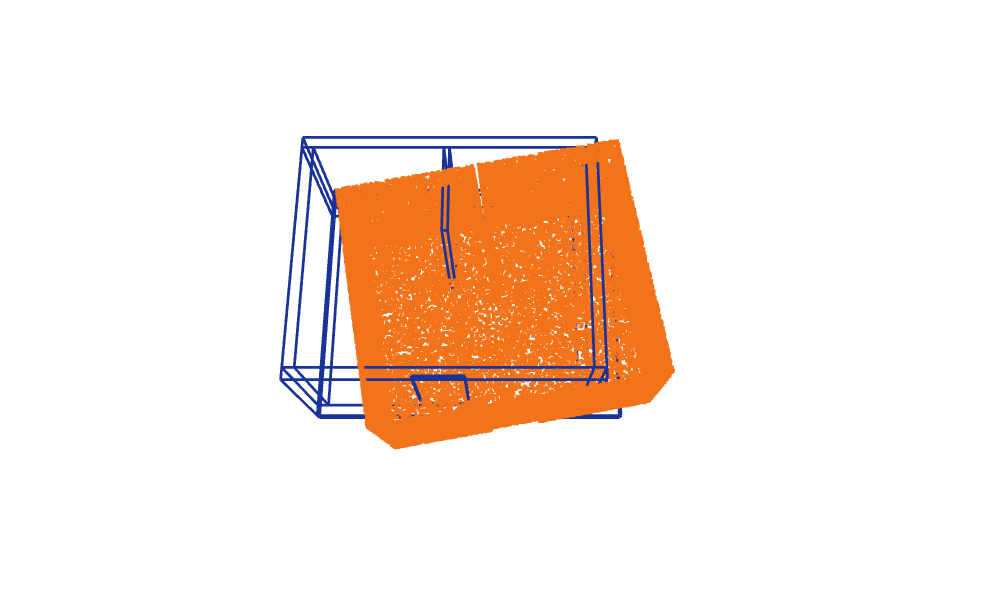

Model (blue edges) and scan (orange points) before registration: the scan sits in its own frame.


In [4]:
def render(items, center, offset, path, size=(1000, 600)):
    """Offscreen Open3D render of (geometry, material) pairs, camera at center + offset; writes a PNG and returns its bytes."""
    r = o3d.visualization.rendering.OffscreenRenderer(*size)
    r.scene.set_background([1, 1, 1, 1])
    r.scene.view.set_post_processing(False)  # keeps colours as given, background pure white
    for i, (g, mat) in enumerate(items):
        r.scene.add_geometry(f"g{i}", g, mat)
    r.scene.camera.look_at(center, np.add(center, offset), [0, 0, 1])
    r.scene.camera.set_projection(40.0, size[0] / size[1], 0.1, 100.0, o3d.visualization.rendering.Camera.FovType.Vertical)
    o3d.io.write_image(str(path), r.render_to_image())
    del r  # free the GPU context now; the process is slow to exit otherwise
    return Path(path).read_bytes()


def material(shader, **kw):
    m = o3d.visualization.rendering.MaterialRecord()
    m.shader = shader
    for k, v in kw.items():
        setattr(m, k, v)
    return m


# The model's elements are axis-aligned boxes, so their bounding boxes draw the model as clean wireframe
model_edges = o3d.geometry.LineSet()
for e in elements:
    box = o3d.geometry.AxisAlignedBoundingBox(e.vertices.min(0), e.vertices.max(0))
    model_edges += o3d.geometry.LineSet.create_from_axis_aligned_bounding_box(box)
model_edges.paint_uniform_color([0.1, 0.2, 0.6])
EDGES, POINTS = material("unlitLine", line_width=2.0), material("defaultUnlit", point_size=3.0)

scan_orange = o3d.geometry.PointCloud(scan)
scan_orange.paint_uniform_color([0.95, 0.45, 0.1])
both = np.concatenate([np.asarray(model_mesh.vertices), np.asarray(scan.points)])
fig1 = render([(model_edges, EDGES), (scan_orange, POINTS)], center=both.mean(0), offset=[0.0, -5.0, 14.0], path=OUT / "fig1_before.png")
display(Image(data=fig1))
print("Model (blue edges) and scan (orange points) before registration: the scan sits in its own frame.")

## 3. Registration: FPFH + RANSAC, then point-to-plane ICP

Both sides are point clouds: the scan, and points sampled from the model mesh. FPFH features on a voxel-downsampled copy give a global RANSAC estimate that needs no starting guess; ICP on the full clouds then refines it. The result is compared with the inverse of the known transform. Translation error is the displacement of the model's centroid, so it does not depend on where the origin happens to be.

Two things found while building this, both relevant for notebook 02:

- **Model side.** The model points are those the scanner positions could see, the same cut as for the scan. With every face of the model (outer faces too), FPFH+RANSAC often converged to a wrong fit: a 180° flip, or the scan's inner wall faces matched to the outer faces one wall thickness away. A real scan also lacks the outer faces, so a real pipeline needs some such cut.
- **Robust ICP.** Plain point-to-plane ICP averages over all correspondences, so the moved wall pulls the whole scan towards it. Both measured errors are printed below. A second ICP pass with a Tukey loss ignores the wall that disagrees with the majority and removes the pull.

RANSAC      rotation error   0.294 deg, translation error    28.5 mm
plain ICP   rotation error   0.096 deg, translation error    15.2 mm
robust ICP  rotation error   0.001 deg, translation error     0.1 mm
registration residual (registered scan to model surface): mean 7.4 mm, median 2.0 mm, 95th percentile 40.8 mm (the moved wall makes the tail)


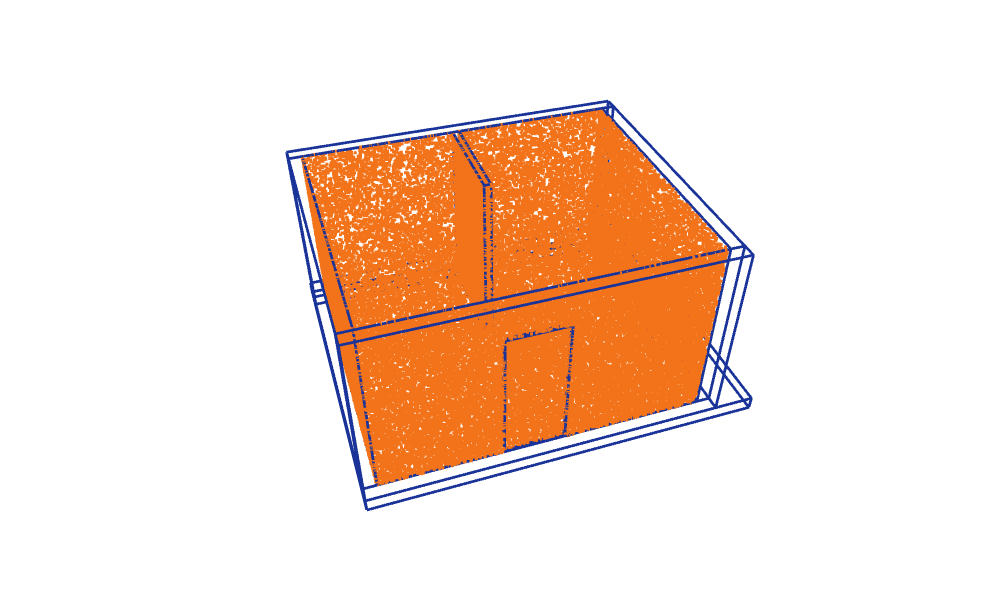

After registration: the scan lies on the model.


In [5]:
model = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(visible_from_scanners(model_mesh, N_MODEL_SAMPLES)))  # from the model, not the as-built geometry


def features(pcd):
    down = pcd.voxel_down_sample(VOXEL)
    down.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=NORMAL_RADIUS, max_nn=30))
    fpfh = o3d.pipelines.registration.compute_fpfh_feature(down, o3d.geometry.KDTreeSearchParamHybrid(radius=FPFH_RADIUS, max_nn=100))
    return down, fpfh


def errors(T_est, T_known, centroid):
    """Rotation (degrees) and centroid displacement (metres) left after applying T_est to a scan moved by T_known."""
    residual = T_est @ T_known  # identity if registration recovered the inverse of T_known
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


reg = o3d.pipelines.registration
scan_down, scan_fpfh = features(scan)
model_down, model_fpfh = features(model)
ransac = reg.registration_ransac_based_on_feature_matching(
    scan_down, model_down, scan_fpfh, model_fpfh, True, RANSAC_DIST,
    reg.TransformationEstimationPointToPoint(False), 3,
    [reg.CorrespondenceCheckerBasedOnEdgeLength(0.9), reg.CorrespondenceCheckerBasedOnDistance(RANSAC_DIST)],
    reg.RANSACConvergenceCriteria(RANSAC_ITERS, RANSAC_CONFIDENCE))

for p in (scan, model):
    p.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=NORMAL_RADIUS, max_nn=30))
plain = reg.registration_icp(scan, model, ICP_DIST, ransac.transformation, reg.TransformationEstimationPointToPlane())
robust = reg.registration_icp(scan, model, ICP_FINE_DIST, plain.transformation,
                              reg.TransformationEstimationPointToPlane(reg.TukeyLoss(TUKEY_K)),
                              reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
T_est = robust.transformation  # scan frame -> model frame

centroid = np.asarray(model_mesh.vertices).mean(0)
for label, T in [("RANSAC", ransac.transformation), ("plain ICP", plain.transformation), ("robust ICP", T_est)]:
    r, t = errors(T, T_known, centroid)
    print(f"{label:11s} rotation error {r:7.3f} deg, translation error {t * 1000:7.1f} mm")
rot_err, trans_err = errors(T_est, T_known, centroid)

registered = o3d.geometry.PointCloud(scan).transform(T_est)
model_scene = o3d.t.geometry.RaycastingScene()
model_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(model_mesh))
residual = model_scene.compute_distance(o3d.core.Tensor(np.asarray(registered.points), dtype=o3d.core.Dtype.Float32)).numpy()
print(f"registration residual (registered scan to model surface): mean {residual.mean() * 1000:.1f} mm, "
      f"median {np.median(residual) * 1000:.1f} mm, 95th percentile {np.percentile(residual, 95) * 1000:.1f} mm "
      f"(the moved wall makes the tail)")

assert rot_err <= GATE_ROT_DEG and trans_err <= GATE_TRANS_M, "registration misses the 05 gate"
assert rot_err <= GATE_ROT_DEG / 10 and trans_err <= GATE_TRANS_M / 10, "inside the gate, but not comfortably"

registered_orange = o3d.geometry.PointCloud(registered)
registered_orange.paint_uniform_color([0.95, 0.45, 0.1])
VIEW_CENTER, VIEW_OFFSET = [2.6, 2.2, 1.0], [-3.0, -9.0, 8.0]
fig2 = render([(model_edges, EDGES), (registered_orange, POINTS)], VIEW_CENTER, VIEW_OFFSET, OUT / "fig2_after.png")
display(Image(data=fig2))
print("After registration: the scan lies on the model.")

## 4. Comparison per element at the LOA30 tolerance

The tolerance is the USIBD LOA30 band: at most 15 mm at 95 % confidence (about 2σ). Every registered scan point is assigned to its nearest model element, and its **signed offset** is the distance to that element's surface along the surface normal (positive = outward, towards the room for an inner face). Points further than 10 cm from every element are ignored.

Verdict rules for this toy:

- **OK**: at least 80 % of the element's points lie within 15 mm.
- **Shifted**: not OK, the median offset is beyond 15 mm, and the points agree with each other (robust spread under 15 mm), i.e. they cluster at a consistent offset.
- **Not confirmed**: fewer than 200 points, or points without a consistent offset. The comparison does not use the scanner positions (CRAS gives none), so a thin element cannot be called missing or not visible; this notebook never reaches that branch, and the check is here to show where it sits.

In [6]:
comp_scene = o3d.t.geometry.RaycastingScene()
normals = []
for e in elements:
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces))
    m.compute_triangle_normals()
    normals.append(np.asarray(m.triangle_normals))
    comp_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(m))  # geometry ids follow this order

pts = np.asarray(registered.points)
closest = comp_scene.compute_closest_points(o3d.core.Tensor(pts, dtype=o3d.core.Dtype.Float32))
geom_id = closest["geometry_ids"].numpy()
prim_id = closest["primitive_ids"].numpy()
foot = closest["points"].numpy()
n_at_foot = np.stack([normals[g][p] for g, p in zip(geom_id, prim_id)])
signed = np.einsum("ij,ij->i", pts - foot, n_at_foot)  # metres, along the surface normal
in_band = np.linalg.norm(pts - foot, axis=1) <= BAND

rows = []
for i, e in enumerate(elements):
    s = signed[(geom_id == i) & in_band]
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma
    frac_ok = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    if n < MIN_POINTS:
        verdict = "not confirmed"
    elif frac_ok >= MIN_FRAC_OK:
        verdict = "OK"
    elif abs(median) > TOL and spread < TOL:
        verdict = "shifted"
    else:
        verdict = "not confirmed"
    rows.append(dict(guid=e.global_id, name=guid_to_name[e.global_id], ifc_class=e.ifc_class, verdict=verdict,
                     n=n, median_mm=round(median * 1000, 1) + 0.0, frac_ok=frac_ok))

print(f"{'GlobalId':22s} {'IFC class':9s} {'name':14s} {'verdict':9s} {'points':>6s} {'median offset':>14s} {'within tol':>10s}")
for r in rows:
    print(f"{r['guid']:22s} {r['ifc_class']:9s} {r['name']:14s} {r['verdict']:9s} {r['n']:6d} {r['median_mm']:11.1f} mm {r['frac_ok']:9.0%}")

by_name = {r["name"]: r for r in rows}
assert by_name[MOVED_WALL]["verdict"] == "shifted"
assert abs(by_name[MOVED_WALL]["median_mm"] - 40.0) <= 5.0, "measured offset should be 40 mm within 5 mm"
assert all(r["verdict"] == "OK" for r in rows if r["name"] != MOVED_WALL)

GlobalId               IFC class name           verdict   points  median offset within tol
1QS95FRfDNohxeW4csKlou IfcWall   Wall South     OK          9068         0.0 mm       99%
2P8mr6uWrT5Q5p8AnSezIh IfcWall   Wall North     OK         10511         0.0 mm       99%
1fvsarFMjVLR$7DsPWlWb3 IfcWall   Wall West      OK          8985         0.0 mm      100%
267XM8hxrIf9OKA6KcvPHU IfcWall   Wall East      shifted     8547        40.0 mm        0%
0C9cNTKMDPcQ9sDN04AEKn IfcSlab   Slab           OK         15099         0.0 mm       99%
1w4lPfpA1IXAWaOonVXQfj IfcDoor   Door           OK          1636         0.0 mm      100%
0UU8SwUwrP_eOxjdnV7NWP IfcWall   Wall Partition OK          7387         0.0 mm      100%


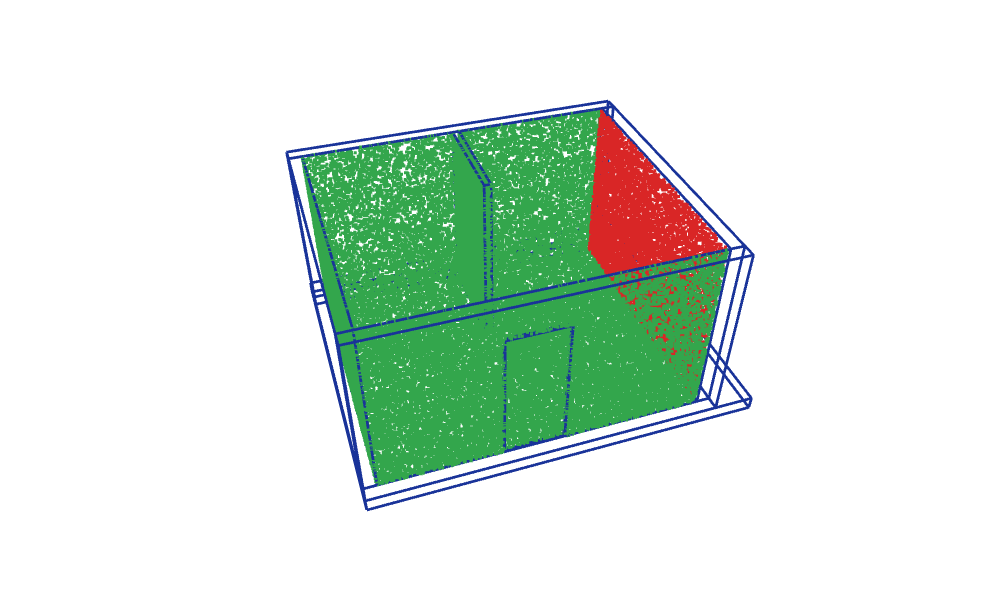

Scan points coloured by their element's verdict: green OK, red shifted (Wall East).


In [7]:
VERDICT_COLOUR = {"OK": [0.2, 0.65, 0.3], "shifted": [0.85, 0.15, 0.15], "not confirmed": [0.5, 0.5, 0.5]}
colours = np.tile([0.8, 0.8, 0.8], (len(pts), 1))  # beyond the band: clutter-grey
for i, r in enumerate(rows):
    colours[(geom_id == i) & in_band] = VERDICT_COLOUR[r["verdict"]]
verdict_cloud = o3d.geometry.PointCloud(registered)
verdict_cloud.colors = o3d.utility.Vector3dVector(colours)
fig3 = render([(model_edges, EDGES), (verdict_cloud, POINTS)], VIEW_CENTER, VIEW_OFFSET, OUT / "fig3_verdicts.png")
display(Image(data=fig3))
print("Scan points coloured by their element's verdict: green OK, red shifted (Wall East).")

## 5. Report: verdicts as IFC properties, issues as BCF

Each element of a copy of the model gets a property set `ScanVsBim_Verdict` (`Verdict`, `MedianOffset_mm`). One BCF 2.1 topic is created per element that is not OK, with a viewpoint whose selection holds that element's GlobalId. Both files are read back and checked.

In [8]:
REPORT_IFC = OUT / "toy_room_verdicts.ifc"
g = ifcopenshell.open(str(MODEL_IFC))
for r in rows:
    el = g.by_guid(r["guid"])
    pset = ifcopenshell.api.run("pset.add_pset", g, product=el, name="ScanVsBim_Verdict")
    ifcopenshell.api.run("pset.edit_pset", g, pset=pset,
                         properties={"Verdict": r["verdict"], "MedianOffset_mm": round(r["median_mm"], 1)})
stable_guids(g)  # the pset entities got random GlobalIds
g.write(str(REPORT_IFC))

back = ifcopenshell.open(str(REPORT_IFC))
for r in rows:
    props = ifcopenshell.util.element.get_psets(back.by_guid(r["guid"]))["ScanVsBim_Verdict"]
    assert props["Verdict"] == r["verdict"] and abs(props["MedianOffset_mm"] - r["median_mm"]) < 0.06
print("verdict properties re-read for", len(rows), "elements")

BCF_PATH = OUT / "toy_room.bcf"
bcf = BcfXml.create_new("Toy room")
for r in rows:
    if r["verdict"] != "OK":
        topic = bcf.add_topic(
            title=f"{r['name']}: {r['verdict']} ({r['median_mm']:+.0f} mm)",
            description=f"Scan points on {r['name']} ({r['ifc_class']}) lie {r['median_mm']:+.1f} mm from the model surface "
                        f"(tolerance {TOL * 1000:.0f} mm, USIBD LOA30). {r['n']} points.",
            author="scan-vs-bim", topic_type="Issue", topic_status="Open")
        topic.add_viewpoint(back.by_guid(r["guid"]))
bcf.save(BCF_PATH)

with zipfile.ZipFile(BCF_PATH) as z:
    names = z.namelist()
    version = ET.fromstring(z.read("bcf.version")).attrib["VersionId"]
    markups = [n for n in names if n.endswith("markup.bcf")]
    viewpoints = [n for n in names if n.endswith(".bcfv")]
    selected = [c.attrib["IfcGuid"] for v in viewpoints for c in ET.fromstring(z.read(v)).iter("Component")]
    titles = [t.text for m in markups for t in ET.fromstring(z.read(m)).iter("Title")]
assert version == "2.1" and len(markups) == 1
assert name_to_guid[MOVED_WALL] in selected
print(f"BCF {version}: {len(markups)} topic, {titles[0]!r}, selection {selected}")

verdict properties re-read for 7 elements
BCF 2.1: 1 topic, 'Wall East: shifted (+40 mm)', selection ['267XM8hxrIf9OKA6KcvPHU']


## Answer

Yes. On a toy room with known answers the chain runs end to end:

- **Registration** (FPFH + RANSAC, then plain and robust ICP) recovers the known transform far inside the 05 gate; the numbers are printed in section 3. The one wall that is 4 cm off does not disturb the robust result, but it does pull plain ICP by about a centimetre.
- **Comparison** at the LOA30 tolerance (15 mm) calls `Wall East` shifted, with a median offset close to the 40 mm that was injected, and every other element OK.
- **Report**: the verdicts are written into a copy of the IFC as properties, and a BCF 2.1 file holds exactly one issue, pointing at the moved wall's GlobalId.

What the toy does not test: clutter, partial coverage, missing or not-visible elements (there are no scanner positions in the comparison), and scale. Those come from the real data in notebooks 01 to 05.